# 04 - Econometric Analysis

**Goal:** apply classical time-series tools to the Rossmann data and understand their strengths and limits relative to a global machine-learning model.

**Scope**

* Stationarity: ADF tests on chain and single-store series.
* Seasonality: additive decomposition and ACF/PACF.
* Regression: OLS of log sales on promotions, weekday, holidays and trend, with robust standard errors.
* Forecasting: SARIMAX on Store 1, evaluated on the untouched 2015 holdout.
* Diagnostics: Ljung-Box, Jarque-Bera, Durbin-Watson, Breusch-Pagan.

All results are produced by `python -m src.econometrics` and stored in `outputs/metrics/econometrics_summary.json`.

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Project root:", PROJECT_ROOT)

Project root: rossmann-sales-forecasting


In [2]:
summary = json.loads((PROJECT_ROOT / "outputs" / "metrics" / "econometrics_summary.json").read_text())
print("Store analysed:", summary["store_id"])
display(pd.DataFrame(summary["stationarity"]).set_index("series"))

Store analysed: 1


,n,adf_statistic,p_value,used_lags,critical_values,stationary_at_5pct
series,,,,,,
Chain daily sales,942,-4.761615,6.436731e-05,20,"{'1%': -3.437470108019385, '5%': -2.8646832620...",True
Chain daily sales - first difference,941,-14.008529,3.750044e-26,19,"{'1%': -3.437470108019385, '5%': -2.8646832620...",True
Chain weekly sales,135,-4.857873,4.209321e-05,2,"{'1%': -3.4808880719210005, '5%': -2.883696619...",True
Chain weekly sales - first difference,134,-8.569848,8.254212e-14,4,"{'1%': -3.482087964046026, '5%': -2.8842185101...",True
Store 1 daily sales,942,-4.368104,3.378835e-04,21,"{'1%': -3.4374778690219956, '5%': -2.864686684...",True
Store 1 daily sales - first difference,941,-11.494179,4.657503e-21,20,"{'1%': -3.4374778690219956, '5%': -2.864686684...",True


**How to read the ADF test.** The null hypothesis is a unit root (non-stationary series). A p-value below 0.05 rejects it. In this sample the test rejects the unit root for every series, including the levels (p < 0.001 for chain daily sales and Store 1). That is plausible with 20+ lags and strong weekly mean reversion, but it should not be read as proof that the series is stationary in every sense: ADF is sensitive to deterministic seasonality and structural breaks.

## 1. Decomposition and autocorrelation

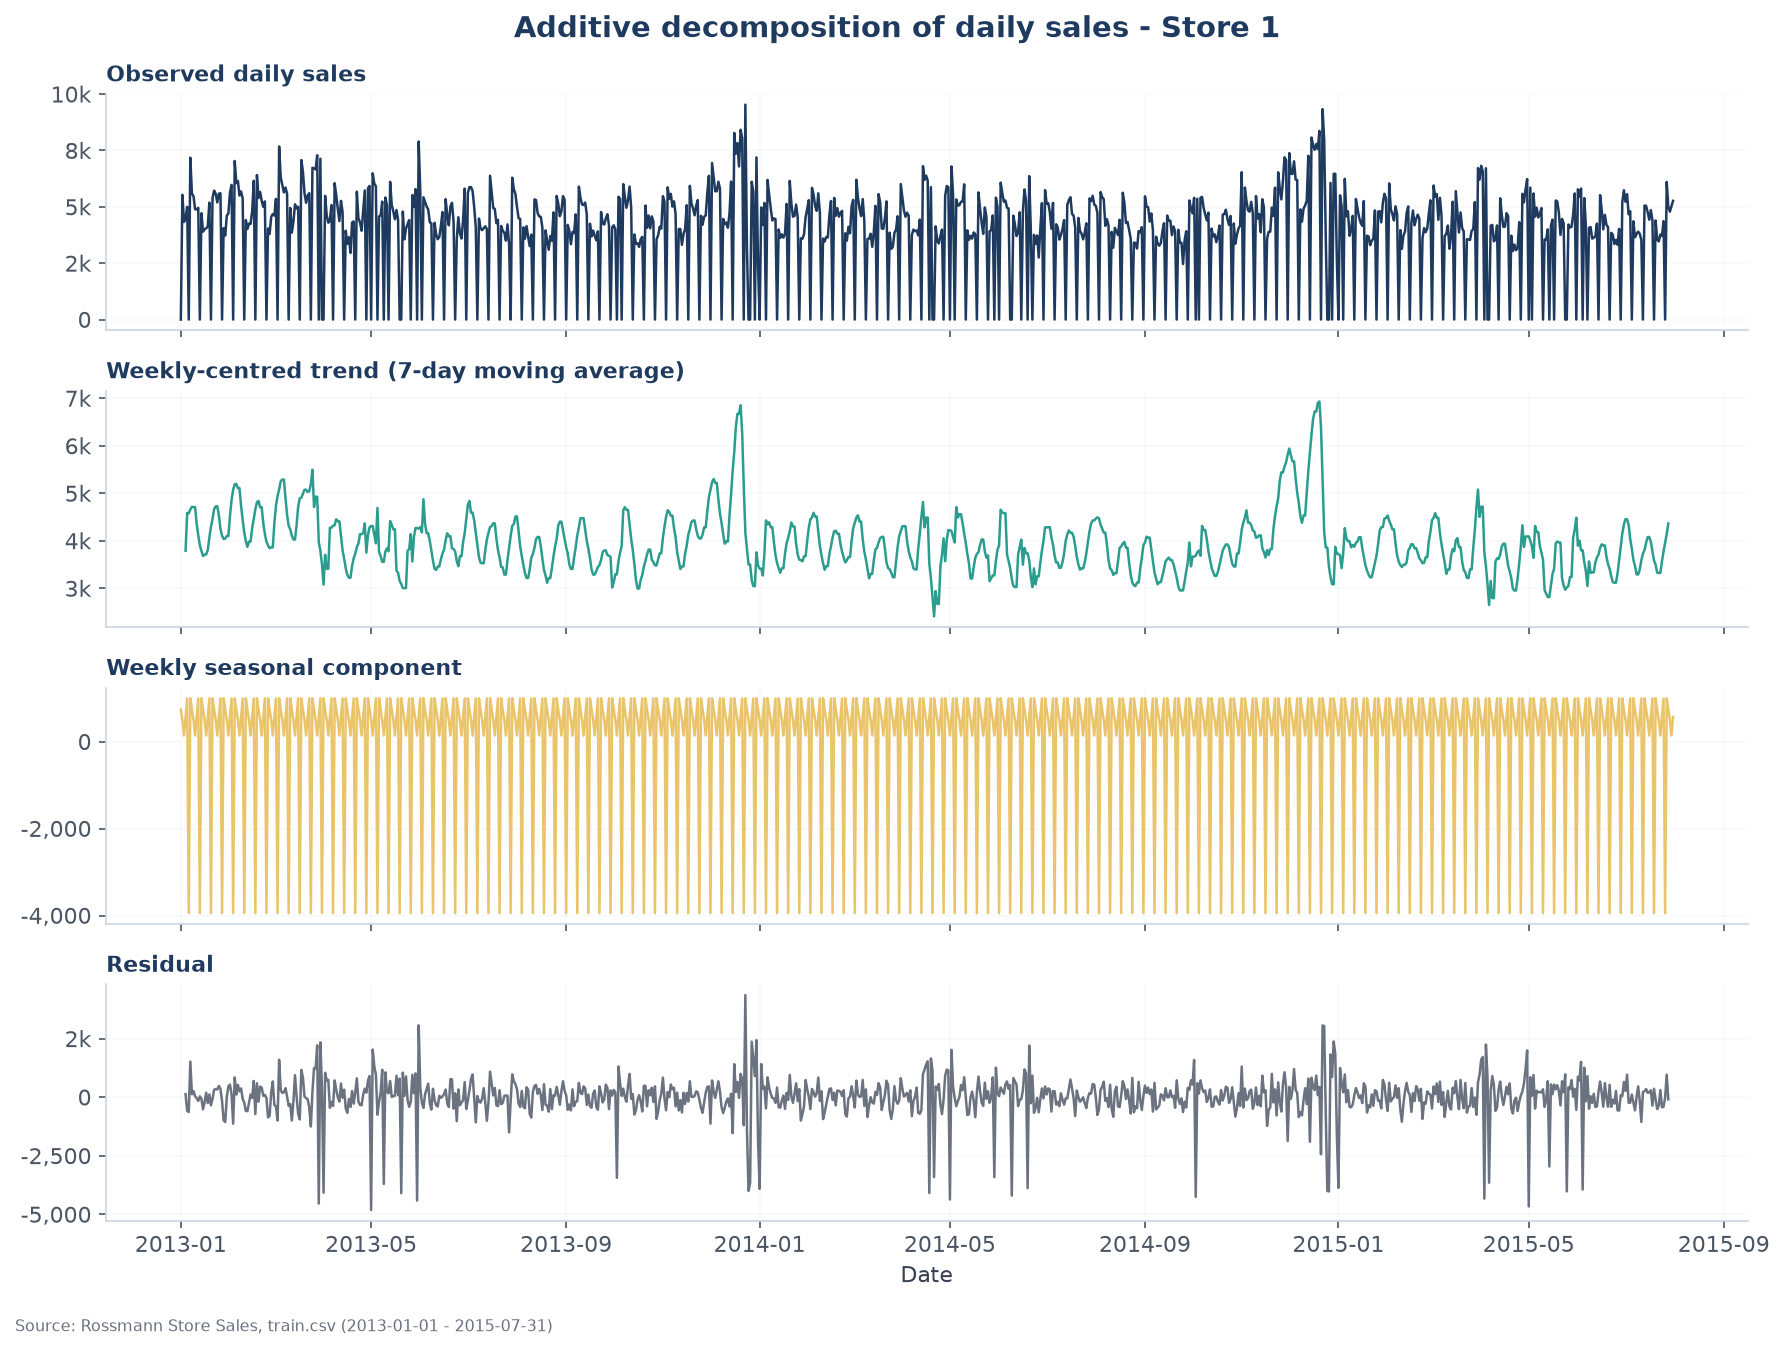

In [3]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig15_ts_decomposition.png"), width=950))

**Interpretation.** The additive decomposition separates a slow-moving trend, a stable 7-day seasonal pattern and a noisy remainder. The seasonal component explains a large share of the variance (seasonal strength is reported in the JSON); the remainder still contains promotion and holiday effects, which is exactly what the regression and SARIMAX models try to capture.

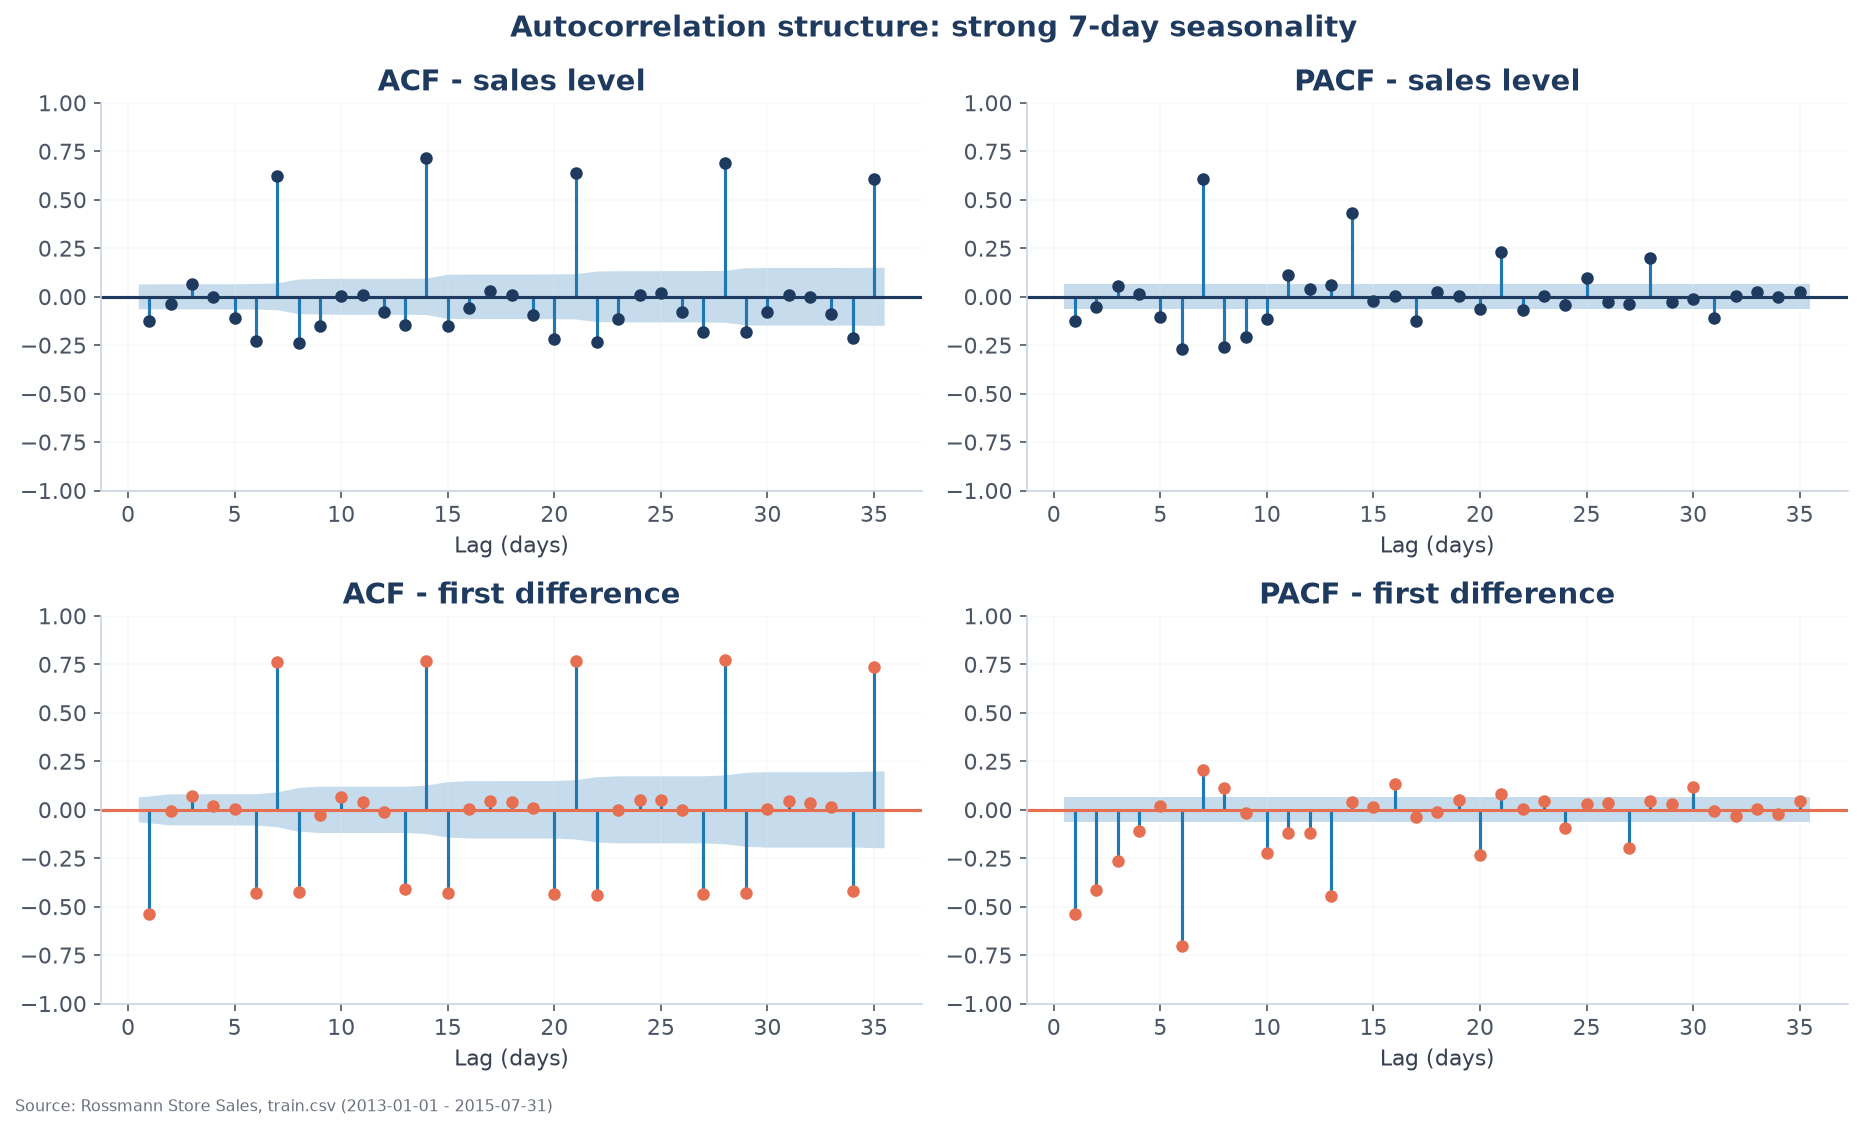

In [4]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig16_acf_pacf.png"), width=950))

**Interpretation.** The ACF of the level decays slowly and shows a clear spike at lag 7, confirming weekly seasonality. The PACF cuts off after a few lags, suggesting a low-order autoregressive structure. After first differencing, the lag-7 spike remains, which is why a seasonal difference (period 7) is appropriate for a single-store model.

**Caveat.** Closed days create zero values every Sunday. This is a deterministic seasonal pattern, not a demand pattern, and it inflates the autocorrelation at multiples of 7.

## 2. OLS regression with robust standard errors

In [5]:
coefs = pd.DataFrame(summary["ols_coefficients"])
display(coefs)
display(pd.Series(summary["ols"], name="value").to_frame())

,term,coefficient,std_error,p_value,ci_low,ci_high,pct_effect
0,Intercept,8.4190,0.0183,0.0000,8.3831,8.4549,453145.2732
1,"C(DayOfWeek, levels=[1, 2, 3, 4, 5, 6])[T.2]",-0.0897,0.0195,0.0000,-0.1280,-0.0515,-8.5839
2,"C(DayOfWeek, levels=[1, 2, 3, 4, 5, 6])[T.3]",-0.1136,0.0188,0.0000,-0.1505,-0.0767,-10.7389
3,"C(DayOfWeek, levels=[1, 2, 3, 4, 5, 6])[T.4]",-0.1393,0.0201,0.0000,-0.1788,-0.0998,-13.0052
4,"C(DayOfWeek, levels=[1, 2, 3, 4, 5, 6])[T.5]",-0.0700,0.0204,0.0006,-0.1101,-0.0299,-6.7614
5,"C(DayOfWeek, levels=[1, 2, 3, 4, 5, 6])[T.6]",0.1215,0.0224,0.0000,0.0776,0.1653,12.9160
6,Promo,0.2754,0.0122,0.0000,0.2514,0.2994,31.7073
7,SchoolHoliday,0.0014,0.0172,0.9355,-0.0324,0.0351,0.1394
8,trend_days,-0.0001,0.0000,0.0000,-0.0001,-0.0001,-0.0104


,value
r_squared,4.444446e-01
adj_r_squared,4.386875e-01
f_statistic,9.500285e+01
f_pvalue,1.535862e-109
n_obs,7.810000e+02
durbin_watson,8.640953e-01
jarque_bera_p,1.008131e-85
breusch_pagan_p,1.087530e-04
residual_std,1.526970e-01


**Interpretation of coefficients.** Coefficients are on the log-sales scale; `pct_effect = exp(beta) - 1` is the approximate percentage change. Promotions are associated with a large positive effect after controlling for weekday, school holidays and trend. Weekday dummies capture the weekly rhythm; the trend coefficient measures average daily growth, which is small and can be negative depending on the store.

**Diagnostics.** The Durbin-Watson statistic is far below 2 (strong positive autocorrelation), Jarque-Bera rejects normality, and Breusch-Pagan rejects homoskedasticity. HC3 standard errors address heteroskedasticity but not autocorrelation; the coefficient standard errors should therefore be read as indicative. This is a classic reason to move from OLS to a time-series model with an explicit error structure.

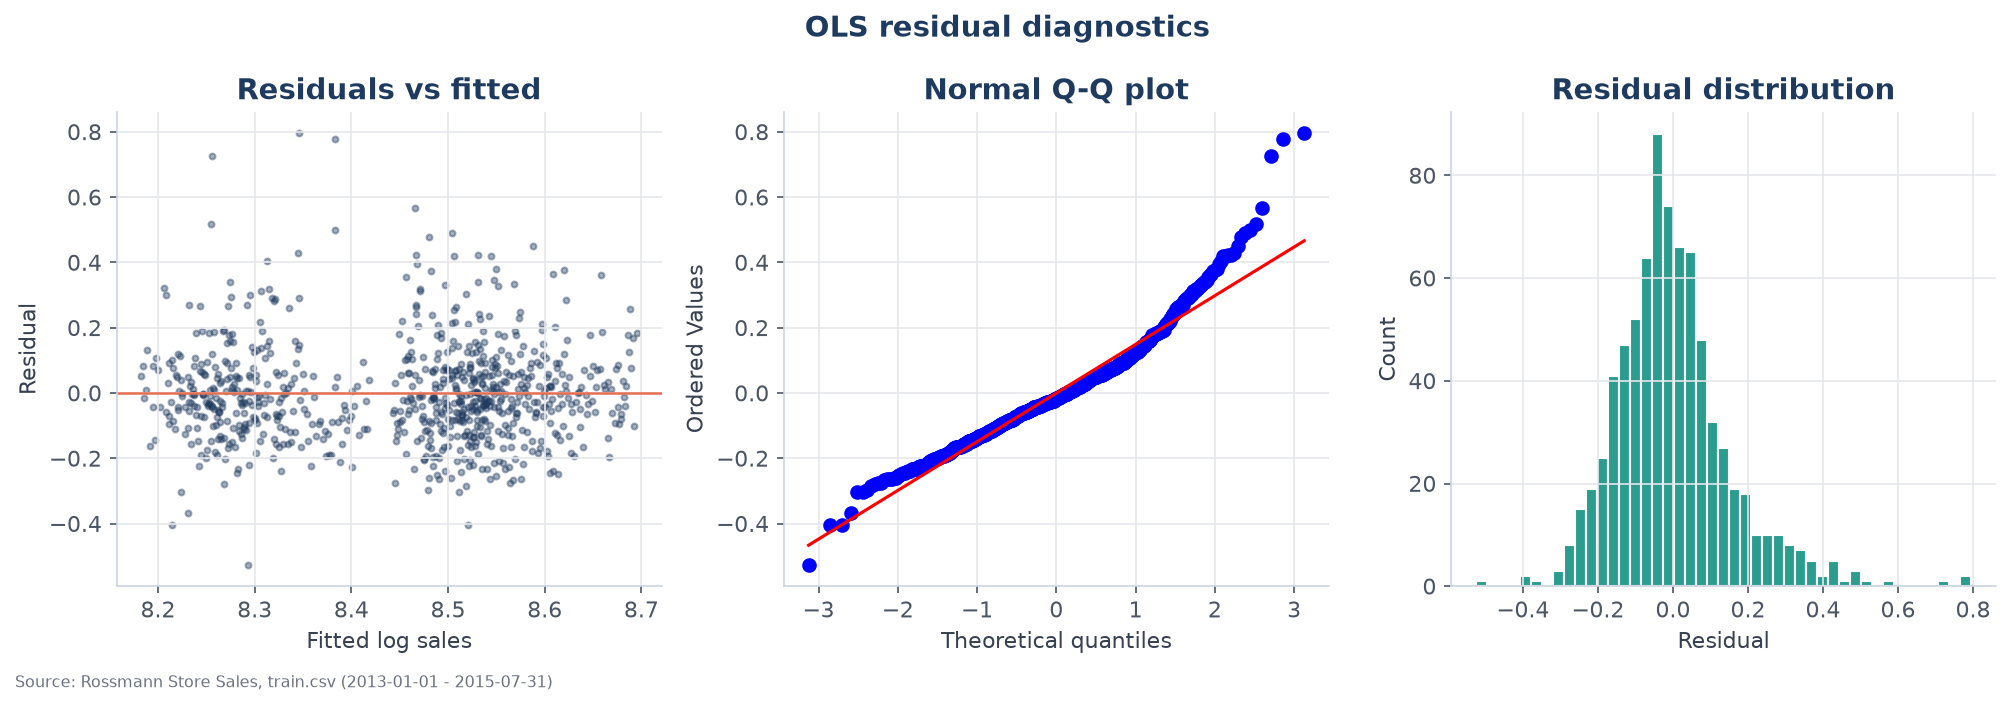

In [6]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig17_regression_diagnostics.png"), width=950))

The residual plots show fat tails and a few large misses around promotions and holidays. The Q-Q plot deviates at both ends. This is expected: the regression is linear in logs and cannot represent interaction effects such as "promotion works differently in large stores".

## 3. SARIMAX on a single store

In [7]:
sarimax = pd.Series(summary["sarimax"], name="value").to_frame()
display(sarimax)
display(pd.Series(summary["sarimax_holdout"], name="value").to_frame())

,value
aic,13806.69737
bic,13883.157928
ljung_box_lag7_p,0.000094
ljung_box_lag14_p,0.000006
jarque_bera_p,0.0
residual_std,684.623063
converged,True
order,"[1, 0, 1]"
seasonal_order,"[1, 1, 1, 7]"


,value
model,sarimax
n_rows_total,47
n_rows_scored,41
rmspe,0.123427
mae,404.06527
rmse,498.31074
wape,0.09136
bias_mean,319.789002
bias_pct_of_mean,0.072305


**Model.** SARIMAX(1,0,1)(1,1,1,7) with exogenous promotion, school-holiday, state-holiday and weekday dummies. It is trained up to 2015-06-14 and evaluated on 2015-06-15 .. 2015-07-31, the same holdout used for the machine-learning models.

**Interpretation.** The model captures the weekly pattern and the promotion effect, but the Ljung-Box test still rejects white-noise residuals at lags 7 and 14: there is remaining autocorrelation that a low-order SARIMA cannot absorb. On this single store the SARIMAX holdout RMSPE is 0.123; the global XGBoost scores 0.126 on the same 41 days, while a global linear regression scores 0.103. The differences are within the noise of a single-store, 41-day comparison. The global model's advantage is scalability and cross-store learning, not automatic superiority on every individual series.

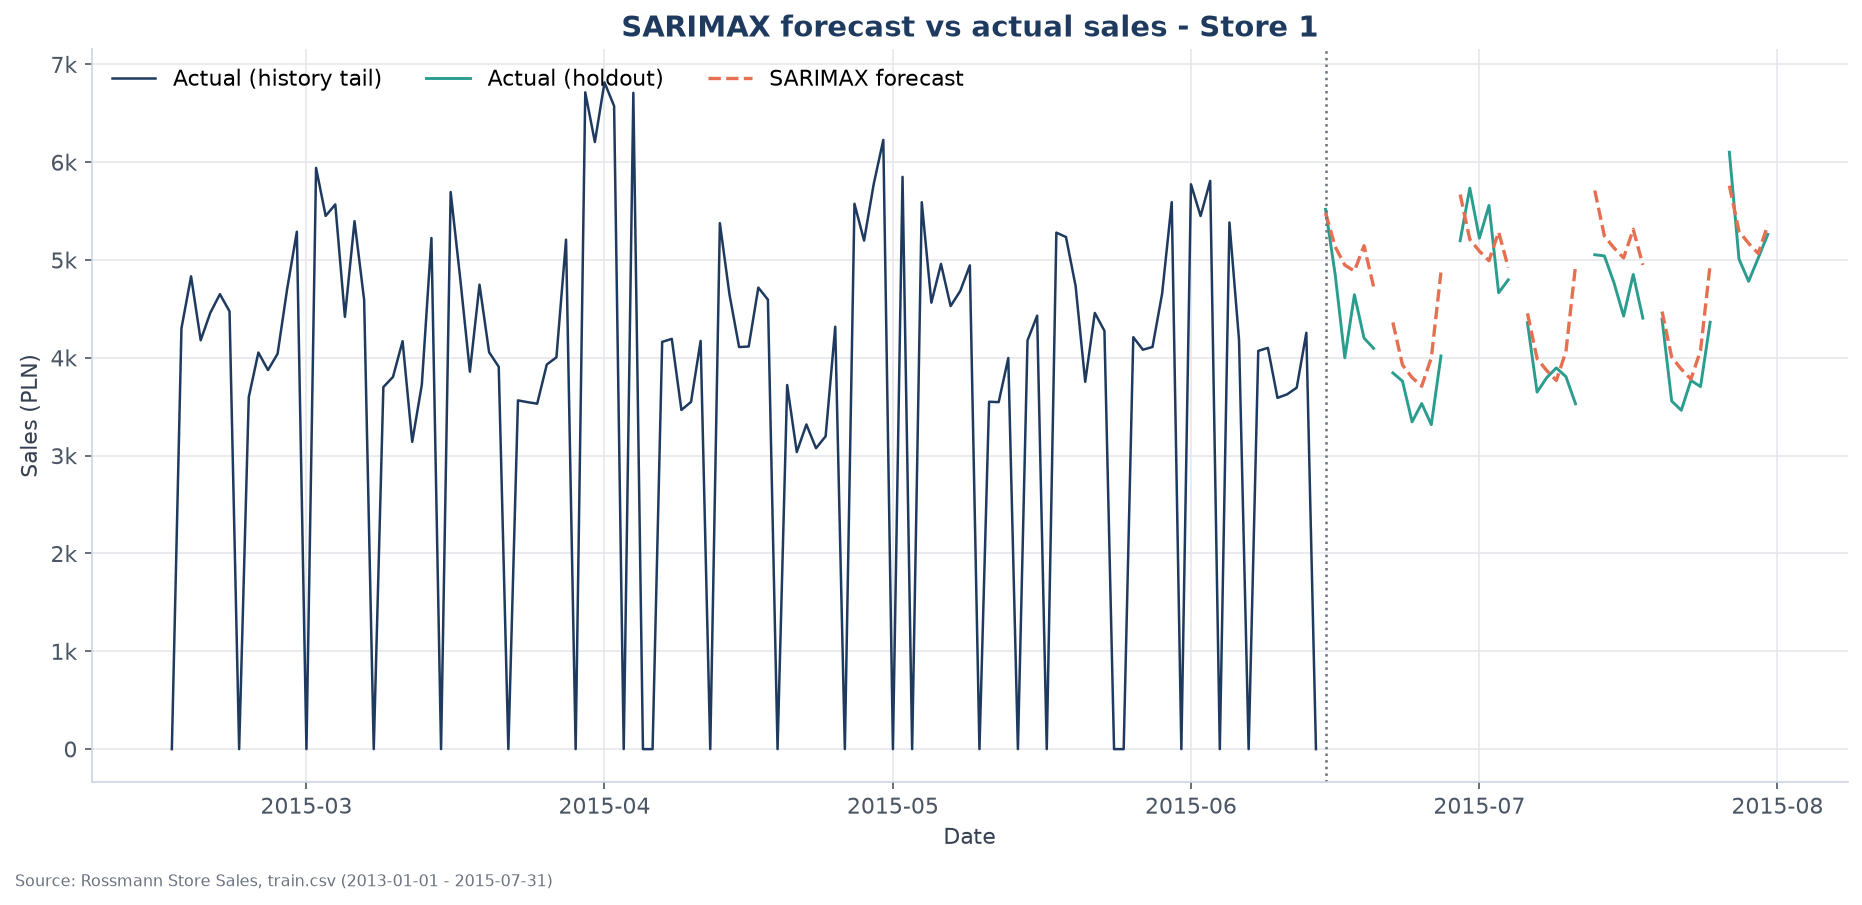

In [8]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig18_sarimax_forecast.png"), width=950))

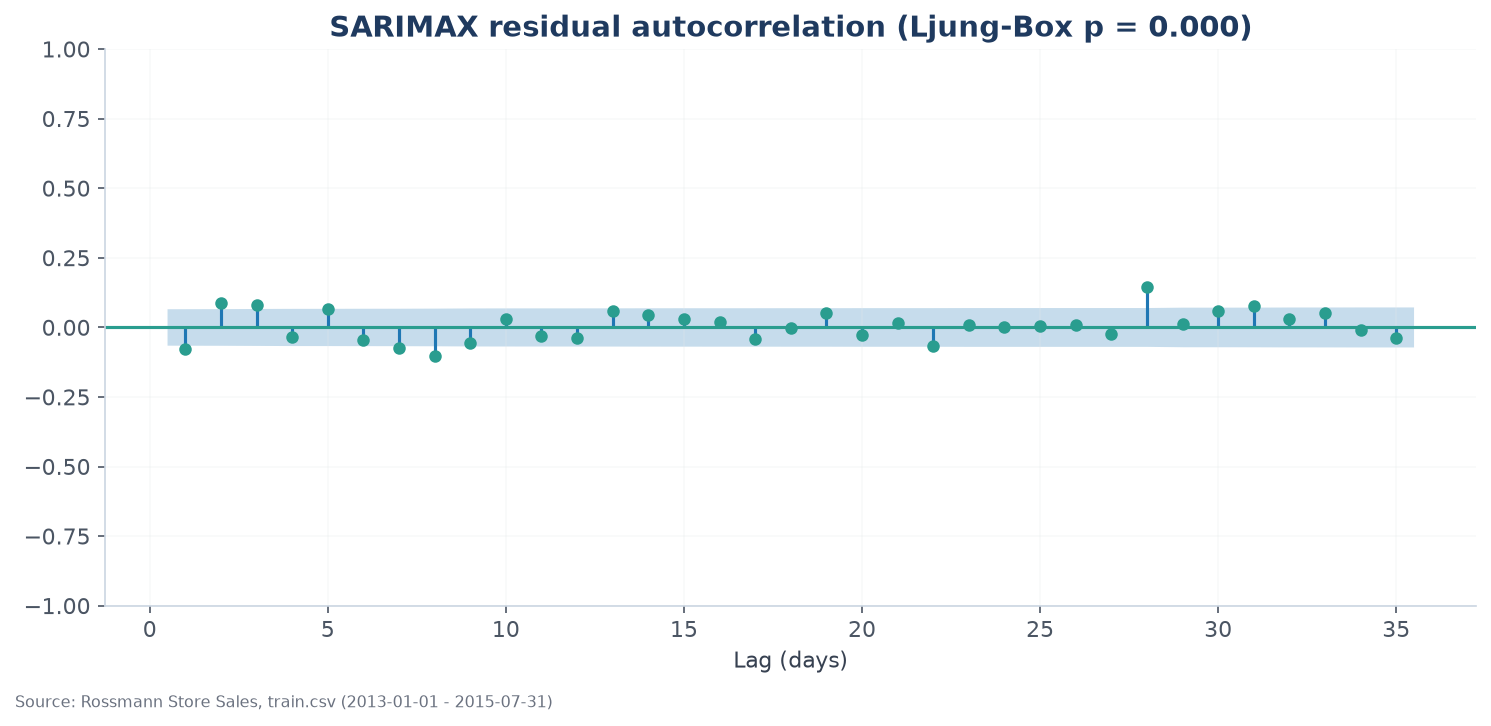

In [9]:
display(Image(filename=str(PROJECT_ROOT / "outputs" / "figures" / "fig19_sarimax_residual_acf.png"), width=950))

In [10]:
comparison = pd.read_csv(PROJECT_ROOT / "outputs" / "metrics" / "store1_model_comparison.csv")
display(comparison)

,model,rmspe,mae,n
0,linear_regression,0.1032,367.0165,41
1,random_forest,0.1115,399.9637,41
2,sarimax,0.1234,404.0653,41
3,xgboost,0.1264,433.7261,41
4,seasonal_naive,0.1782,713.4390,41
5,historical_average,0.2017,669.7416,41


## 4. What classical models are good for - and where they stop

**Strengths**

* Interpretable parameters: a promotion coefficient, a weekday effect, a trend.
* Explicit uncertainty intervals from the state-space model.
* Transparent diagnostics that expose autocorrelation and heteroskedasticity.
* No feature leakage: the model uses the series' own past and known exogenous variables.

**Limits**

* One model per store is computationally wasteful and ignores cross-store learning.
* Linear structure misses interactions (promotion x store type, holiday x weekday).
* Seasonal ARIMA needs a long, regular series; closures and missing days complicate it.
* A single-store model cannot use the behaviour of similar stores to improve a noisy series.

**Conclusion.** SARIMAX is a useful benchmark and an interpretability tool, but the production forecast in this project is a global gradient-boosted model with direct multi-horizon features. The comparison is reported honestly, including the cases where the classical model wins (some stores, some weeks).